### Hypothesis Testing Simulation
### Objective: Simulate A/B testing to understand the effects of different variables on user engagement.

#### PROJECT DESCRIPTION

In [ ]:
# Description:

# Simulate user response data for two web page designs (A and B).
# Use Python to generate random user data, including click-through rate, time spent on a page, and conversion.
# Hypothesis testing will be performed to determine if there is a statistically significant difference between the two designs.
# Calculate and interpret the confidence interval to understand the precision of the estimated effects.

#### WHAT IS A/B TESTING

In [ ]:
A/B testing, also known as split testing, is a method of comparing two versions of a webpage, app, or other user experiences
to determine which one performs better. 

#### KEY CONCEPTS IN A/B TESTING:

##### Case study

In [ ]:
# Case study - shein app interface (current version) -  The black design
# Case study - shein app interface (New version) - The red design

##### Version Creation:

In [ ]:
# Design black: the control group (current version)
# Design red : the treatment  group (the new version)

##### The Features of the data to be generated are below

In [ ]:
# Impressions: Total views generated (base metric).
# Reach: Fraction of impressions seen by unique users (50%–100%).
# Clicks: Fraction of reach where users interact (5%–20%).
# View Content: Fraction of clicks where users view detailed content (50%–90%).
# Purchases: Fraction of view content where users make purchases (10%–30%).
# Click through rate: evaluate how engaging the content or ads are in driving clicks.
# Time spent on page: measures how users engaged(user engagemnet) or how interested users are in the content.
# Conversion: measures the effectiveness of those clicks leading to purchases

##### The matrics ( the outcome to measure )

In [ ]:
# Impressions - Sum
# Clicks - Sum
# Purchases - Sum
# Click-Through Rate - Mean
# Conversion Rate - Mean
# Time Spent on Page - Mean

##### Hypothesis testing

In [ ]:
# Null Hypothesis (H₀): Changing the design from black to red will not make any real difference on how users 
# interact with the website. Any changes we see are just random.

# Alternative Hypothesis (H₁): Changing the design from black to red will make users more engaged with the website,
# leading to more clicks, more time spent on the page, or higher conversions

##### Generating random user_data and Saving the Dataframe as a csv file

In [2]:
import random 
import numpy as np  
import pandas as pd  

def generate_random_user_data(num_users, seed_value=None):
    """
    Generate random user interaction data for Shein's Black Friday A/B testing, 
    return it as a dataframe and save it as a csv file.

    Parameters:
    num_users (int): Number of users to generate data for.
    seed_value (int, optional): A value to seed the random number generator for reproducibility. Default is None.

    Returns:
    pd.DataFrame: A pandas DataFrame containing the generated user data.
    """
    
    # Set the seed for reproducibility if provided
    if seed_value is not None:
        random.seed(seed_value)  # Seed the random module.
        np.random.seed(seed_value)  # Seed the NumPy random generator.
    
    # Initialize an empty list to store generated user data.
    data = []  
    
    # Define the two designs being tested(A and B)
    designs = ['black', 'red'] 

    # Iterate over user IDs from 1 to num_users.
    for user_id in range(1, num_users + 1):  
        impressions = random.randint(500, 1000)  # Randomly generate impressions between 500 and 1000.
        reach = random.randint(int(impressions * 0.5), impressions)  # Ensure reach is <= impressions.
        
          # Generate clicks based on reach.
        clicks = random.randint(int(reach * 0.05), max(int(reach * 0.2), int(reach * 0.05) + 1))  
          # Generate views based on clicks.
        view_content = random.randint(int(clicks * 0.5), max(int(clicks * 0.9), int(clicks * 0.5) + 1)) 
          # Generate purchases based on views
        purchases = random.randint(int(view_content * 0.1), max(int(view_content * 0.3), int(view_content * 0.1) + 1))
        
        # Calculate conversion metrics, CTR and conversion rate, avoiding division by zero.
        click_through_rate = clicks / impressions if impressions > 0 else 0  
        conversion_rate = purchases / clicks if clicks > 0 else 0   
        
        # Append a dictionary with all the user metrics to the data list.
        data.append({  
            'User ID': user_id,  
            'Design': random.choice(designs),  
            'Impressions': impressions,  
            'Reach': reach,  
            'Clicks': clicks,  
            'View Content': view_content,  
            'Purchases': purchases,  
            'Click-Through Rate': click_through_rate,  
            'Time Spent on Page (secs)': random.randint(30, 300),  
            'Conversion': conversion_rate  
        })

    # Convert the list of dictionaries into a pandas DataFrame.
    Shein_data = pd.DataFrame(data)  

    return Shein_data  # Return the generated DataFrame.

# Generate data for 400 users with a fixed seed for reproducibility.
shein_user_data = generate_random_user_data(num_users=400, seed_value=42)  

# Define the file path for saving the data
csv_file_path = 'shein_user_data.csv' 
# Save the DataFrame as a CSV file with a comma delimiter
shein_user_data.to_csv(csv_file_path, index=False, sep=',')  

# Print a confirmation message.
print(f"Data has been saved to {csv_file_path}")  


Data has been saved to shein_user_data.csv


##### Importing the CSV file 

In [3]:
import pandas as pd  
import numpy as np  
from typing import Optional 

def read_dataset(file_path: str = 'shein_user_data.csv', 
                 delimiter: str = ',', 
                 na_values: Optional[list] = None,
                 dtype_dict: Optional[dict] = None) -> Optional[pd.DataFrame]:
    """
    Reads a dataset from a file into a pandas DataFrame, handles errors, prints data types, 
    and provides missing values information.

    Parameters:
    -----------
    file_path : str, optional
        The path to the dataset file. Defaults to 'shein_ab_test_summary.csv'.
    delimiter : str, optional
        The delimiter used in the CSV file. Defaults to ','.
    na_values : list or dict, optional
        Additional strings to recognize as NA/NaN values.
    dtype_dict : dict, optional
        Dictionary of column names and their expected data types.

    Returns:
    --------
    pd.DataFrame or None
        Returns the DataFrame if successful, otherwise None.
    """
    try:
        # Read the CSV file with additional parameters
        Shein_data = pd.read_csv(file_path, delimiter=delimiter, na_values=na_values, dtype=dtype_dict)
        
        # Print success message and dataset dimensions.
        print("File loaded successfully!")  
        print(f"Dataset dimensions: {Shein_data.shape[0]} rows, {Shein_data.shape[1]} columns")  
        
        # Print the data types as a dictionary
        print("\nData Types of Columns: ") 
        for column, dtype in Shein_data.dtypes.to_dict().items():  
            print(f"{column}: {dtype}")  

        # Handle and display missing values and Notify if there are no missing values.
        missing_values = Shein_data.isnull().sum()  
        if missing_values.sum() > 0:  
            print("\nMissing Values Overview:")  
            print(missing_values[missing_values > 0])  
        else:
            print("\nNo missing values detected in the dataset.")   
        # Return the DataFrame.
        return Shein_data  
    
    # Exception handling
    except FileNotFoundError:  # Handle file not found error.
        print(f"Error: The file '{file_path}' was not found. Please check the file path.")
    
    except pd.errors.EmptyDataError:  # Handle empty or corrupted file error.
        print(f"Error: The file '{file_path}' is empty or corrupted. No data to load.")
    
    except pd.errors.ParserError:  # Handle CSV parsing errors.
        print(f"Error: Unable to parse the file '{file_path}'. Check if the file is a valid CSV.")
    
    except Exception as e:  # Handle unexpected errors.
        print(f"An unexpected error occurred: {str(e)}")
    
    # Return None if any error occurs
    return None

# Define the path to the CSV file and Call the function to read the dataset.
file_path = 'shein_user_data.csv'  
Shein_data = read_dataset(file_path)  

 # Verify that the dataset was loaded successfully and display the first 10 rows
if Shein_data is not None: 
    print("\nFirst 10 Rows of the Dataset:") 
    print(Shein_data.head(10).to_string(index=False))  
else:
    print("Failed to load the dataset.") # Notify if the dataset could not be loaded. 

File loaded successfully!
Dataset dimensions: 400 rows, 10 columns

Data Types of Columns: 
User ID: int64
Design: object
Impressions: int64
Reach: int64
Clicks: int64
View Content: int64
Purchases: int64
Click-Through Rate: float64
Time Spent on Page (secs): int64
Conversion: float64

No missing values detected in the dataset.

First 10 Rows of the Dataset:
 User ID Design  Impressions  Reach  Clicks  View Content  Purchases  Click-Through Rate  Time Spent on Page (secs)  Conversion
       1  black          827    470      26            17          2            0.031439                        101    0.076923
       2    red          877    490      93            51         14            0.106043                         46    0.150538
       3  black          515    304      28            17          5            0.054369                        131    0.178571
       4  black          866    765     127            97         22            0.146651                        259    0.173228

##### Analysing the A/B test

In [4]:
import pandas as pd  
import numpy as np  

def analyze_ab_test_results(Shein_data: pd.DataFrame) -> pd.DataFrame:
    """
    Analyze A/B test results by aggregating data per design.
    
    Parameters:
    -----------
  Shein_data : pd.DataFrame
        Input DataFrame with user interaction data.
    
    Returns:
    --------
    pd.DataFrame
        Aggregated results of A/B test by design.
    """
    # Group by Web Page Design, aggregate key metrics, and Calculate the mean conversion rate, 
    # time spent on the page and 
    ab_test_summary = Shein_data.groupby('Design').agg({  
        'Impressions': 'sum',  
        'Clicks': 'sum', 
        'Purchases': 'sum',  
        'Click-Through Rate': 'mean',  
        'Conversion': 'mean',   
        'Time Spent on Page (secs)': 'mean' 
    }).reset_index()  # Reset the index to make 'Design' a regular column.
    
    # Return the summarized A/B test results.
    return ab_test_summary  

# Call the function to analyze A/B test results.
result = analyze_ab_test_results(Shein_data)  

# Print the aggregated results as a string, keeping the index visible.
print(result.to_string(index=True))  

  Design  Impressions  Clicks  Purchases  Click-Through Rate  Conversion  Time Spent on Page (secs)
0  black       136214   12358       1709            0.090965    0.136959                 165.404255
1    red       161548   15065       2081            0.093621    0.137683                 177.183962


##### Visualizing the result

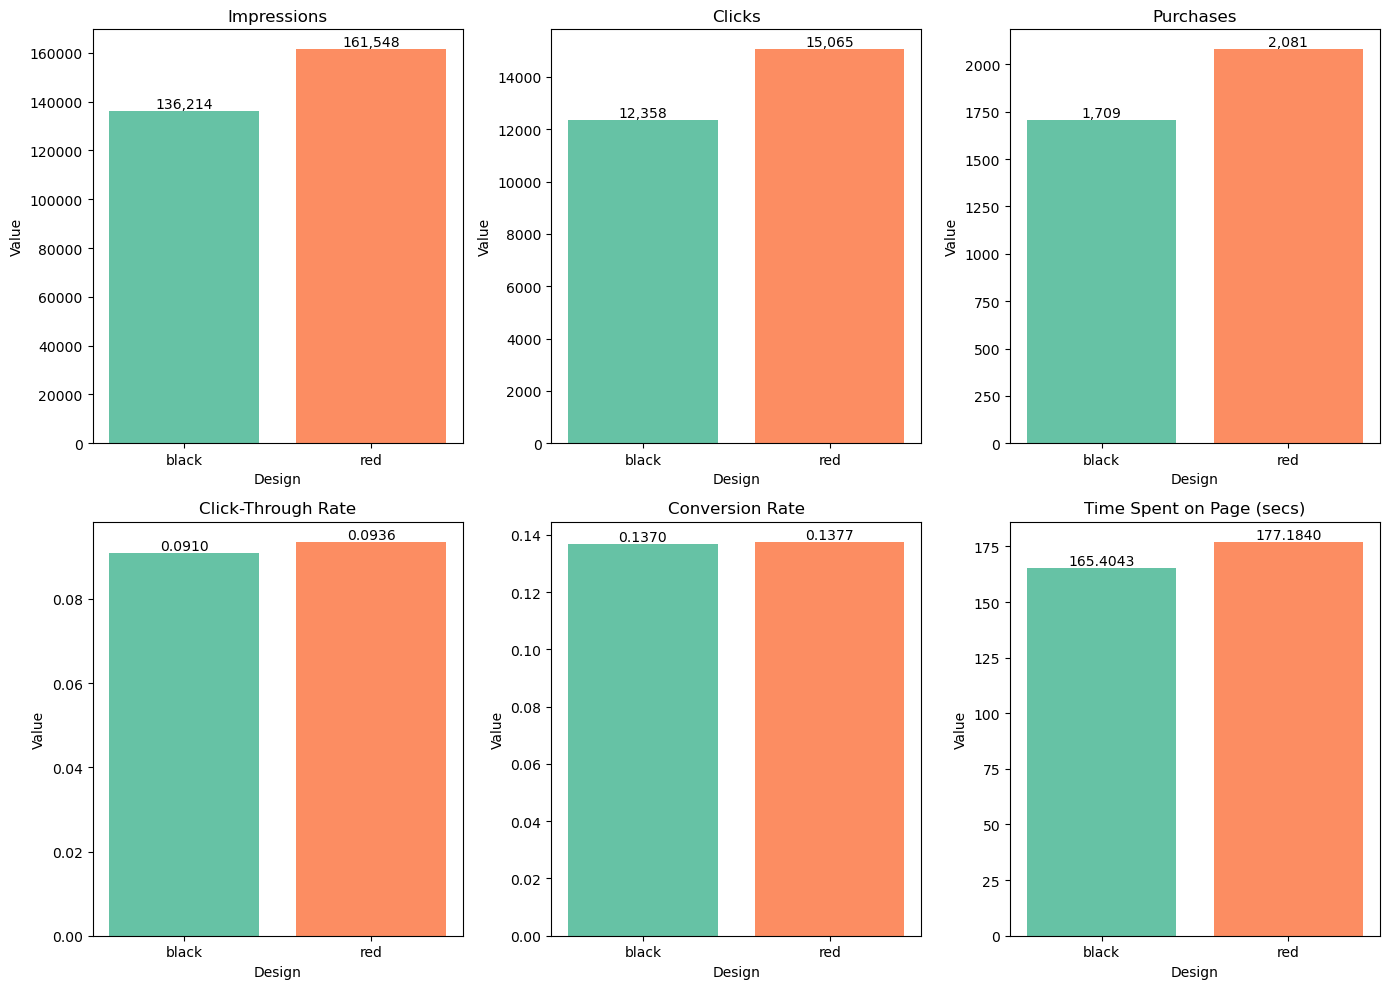

In [5]:
import pandas as pd  
import matplotlib.pyplot as plt  
import seaborn as sns  

def plot_the_design_metrics():
    """
    Plot the A/B test results for different metrics by design (black and red).
    Metrics include:
    - Impressions
    - Clicks
    - Purchases
    - Click-Through Rate
    - Conversion Rate
    - Time Spent on Page
    
    Returns:
    --------
    None
    """
    # Data to plot
    data = {
        'Design': ['black', 'red'],  
        'Impressions': [136214, 161548], 
        'Clicks': [12358, 15065], 
        'Purchases': [1709, 2081], 
        'Click-Through Rate': [0.090965, 0.093621],  
        'Conversion Rate': [0.136959, 0.137683],  
        'Time Spent on Page (secs)': [165.404255, 177.183962]  
    }
    
    # Convert the dictionary into a pandas DataFrame.
    shein_metrics = pd.DataFrame(data)  

    # Create a grid of 2 rows and 3 columns for subplots
    fig, axs = plt.subplots(2, 3, figsize=(14, 10))  .
    axs_flat = axs.flatten()  # Flatten the 2D array of axes for easy iteration.
    
    # List of metrics to plot
    metrics = ['Impressions', 'Clicks', 'Purchases', 'Click-Through Rate', 'Conversion Rate', 'Time Spent on Page (secs)']
    
    # Iterate through the metrics list to plot
    for i, metric in enumerate(metrics):  
        # Create a bar plot for each metric.
        axs_flat[i].bar(shein_metrics['Design'], shein_metrics[metric], color=sns.color_palette("Set2", 2))
        axs_flat[i].set_title(metric) 
        axs_flat[i].set_xlabel('Design')  
        axs_flat[i].set_ylabel('Value')  
        
        # Add value labels on top of each bar
        for j, v in enumerate(shein_metrics[metric]): 
            if isinstance(v, float):  # For metrics like rates, format as decimal.
                label = f'{v:.4f}'  # Format as 4 decimal places.
            else:  # For integer metrics like impressions, format as integer.
                label = f'{v:,.0f}'  # Add commas for thousands.
            axs_flat[i].text(j, v, label, ha='center', va='bottom')  
    
    # Adjust subplot spacing for better layout.
    plt.tight_layout()  
    plt.show()  

# Call the function to generate the plot
plot_the_design_metrics()

##### Stating  the observed and expected frequencies for the shein design

##### Performing the chi-square test

In [14]:
import numpy as np  
import pandas as pd 
from scipy.stats import chi2_contingency 

def perform_chi_square_test(data):
    """
    Perform a chi-square test to determine the probability of observed vs expected frequencies
    across metrics of design data.
    
    Parameters:
    -----------
    data : pd.DataFrame
        DataFrame containing the metrics for both designs
        (e.g., impressions, clicks, purchases,
        Click-Through Rate, Conversion Rate, Time Spent on Page (secs)).
        
    Returns:
    --------
    str
        A formatted string with chi-square statistic, p-value, degrees of freedom, expected frequencies, 
        and interpretation.
    """
    # Extract relevant columns as a contingency table
    try:
        # Select columns of interest and convert them to a NumPy array for chi-square computation.
        contingency_table = data[['Impressions', 'Clicks', 'Purchases', 'Click-Through Rate',
                                  'Conversion Rate', 'Time Spent on Page (secs)']].to_numpy()
    except KeyError:
        # Raise an error if required columns are missing from the DataFrame.
        raise ValueError("The DataFrame must contain 'Impressions', 'Clicks', 'Purchases', 'Click-Through Rate', "
                         "'Conversion Rate', 'Time Spent on Page (secs)' columns.")

    # Perform chi-square test
    chi_square_stat, p_value, dof, expected = chi2_contingency(contingency_table)

    # Format the expected frequencies to avoid scientific notation
    expected_formatted = np.array2string(expected, formatter={'float_kind': lambda x: f"{x:.4f}"})

    # Interpretation
    alpha = 0.05  # Significance level
    interpretation = (
        "Statistically significant difference (reject the null hypothesis)." 
        if p_value < alpha
        else "No statistically significant difference (fail to reject the null hypothesis)."  
    )

    # Return formatted results
    result = (
        f"Chi-square statistic: {chi_square_stat:.2f}\n"  
        f"P-value: {p_value:.2f}\n"  
        f"Degrees of Freedom: {dof}\n"  
        f"Expected Frequencies:\n{expected_formatted}\n"  
        f"Interpretation: {interpretation}"  
    )
    return result


# Set pandas options to format floats without scientific notation
pd.options.display.float_format = '{:.2f}'.format

data = {
    'Design': ['black', 'red'],  
    'Impressions': [136214, 161548],  
    'Clicks': [12358, 15065],  
    'Purchases': [1709, 2081],  
    'Click-Through Rate': [0.090965, 0.093621],  
    'Conversion Rate': [0.136959, 0.137683], 
    'Time Spent on Page (secs)': [165.404255, 177.183962]  
}

# Create a DataFrame from the data dictionary.
df = pd.DataFrame(data)

# Perform the chi-square test and print results
result = perform_chi_square_test(df)
print(result)


Chi-square statistic: 6.17
P-value: 0.29
Degrees of Freedom: 5
Expected Frequencies:
[[136030.4740 12528.0045 1731.4348 0.0843 0.1255 156.5090]
 [161731.5260 14894.9955 2058.5652 0.1003 0.1492 186.0792]]
Interpretation: No statistically significant difference (fail to reject the null hypothesis).


##### Performing the confidence interval

In [7]:
import pandas as pd  # Importing pandas for data manipulation.
import numpy as np  # Importing NumPy for numerical operations.
from scipy import stats  # Importing stats from SciPy for statistical calculations.

def analyze_confidence_intervals(data, confidence=0.95):
    """
    Calculate the confidence interval for a proportion using the normal approximation
    and interpret confidence intervals for design metrics.
    
    Parameters:
    -----------
    data : DataFrame
        DataFrame containing metrics for both designs.
    confidence : float, optional
        Confidence level (default 0.95 for 95% confidence).
        
    Returns:
    --------
    dict
        Results and interpretations for each metric.
    """
    # List of metrics to analyze.
    metrics = ['Impresons', 'Clicks', 'Purchases', 'Click-Thrsiough Rate', 'Conversion Rate', 
               'Time Spent on Page (secs)']
    results = {}  # Dictionary to store results for each metric.
    
    for metric in metrics:
        # Extract the metric values for the designs.
        values = data[metric].values
        
        # Calculate the mean of the metric across designs.
        mean = np.mean(values)
        
        # Calculate the standard error of the mean (SEM).
        std_error = stats.sem(values)
        
        # Calculate the confidence interval using the t-distribution.
        ci = stats.t.interval(confidence, 
                            len(values)-1,  # Degrees of freedom.
                            loc=mean,  # Mean value.
                            scale=std_error)  # Standard error.
        
        # Calculate the difference in metric values between designs.
        difference = values[1] - values[0]  # red - black.
        
        # Determine performance comparison between designs.
        if difference > 0:
            performance = "better"  # Red design outperforms black.
        elif difference < 0:
            performance = "worse"  # Red design underperforms compared to black.
        else:
            performance = "same"  # No difference in performance.
        
        # Create an interpretation of the results.
        interpretation = (
            f"The red design performed {performance} than the black design for {metric.lower()}, "
            f"with {confidence*100}% confidence that the true value lies between "
            f"{ci[0]:.0f} and {ci[1]:.0f}. "
            f"The average value was {mean:.0f}."
        )
        
        # Store the results for the current metric.
        results[metric] = {
            'mean': mean,  # Mean value of the metric.
            'confidence_interval': ci,  # Confidence interval for the metric.
            'difference': difference,  # Difference between designs.
            'interpretation': interpretation  # Text interpretation of results.
        }
    
    return results  # Return the results dictionary.

# Create sample data as a DataFrame.
df = pd.DataFrame({
    'Design': ['black', 'red'],  
    'Impressions': [136214, 161548],  
    'Clicks': [12358, 15065],  
    'Purchases': [1709, 2081],  
    'Click-Through Rate': [0.090965, 0.093621],  
    'Conversion Rate': [0.136959, 0.137683],  
    'Time Spent on Page (secs)': [165.404255, 177.183962] 
})

# Calculate confidence intervals 
results = analyze_confidence_intervals(df)

# Print formatted results for each metric.
for metric, data in results.items():
    print(f"\n{metric}")  
    print("-" * len(metric))  
    print(data['interpretation'])  


Impressions
-----------
The red design performed better than the black design for impressions, with 95.0% confidence that the true value lies between -12068 and 309830. The average value was 148881.

Clicks
------
The red design performed better than the black design for clicks, with 95.0% confidence that the true value lies between -3486 and 30909. The average value was 13712.

Purchases
---------
The red design performed better than the black design for purchases, with 95.0% confidence that the true value lies between -468 and 4258. The average value was 1895.

Click-Through Rate
------------------
The red design performed better than the black design for click-through rate, with 95.0% confidence that the true value lies between 0 and 0. The average value was 0.

Conversion Rate
---------------
The red design performed better than the black design for conversion rate, with 95.0% confidence that the true value lies between 0 and 0. The average value was 0.

Time Spent on Page (secs)
